In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.append("..")
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
from src.metrics import portfolio_metrics, benchmark_metrics
from src.plot import cumulative_returns, drawdown
from config import rf_daily, method

In [2]:
BASE_DIR = Path().resolve().parent
price_path = BASE_DIR / "results" / "prices"
portfolio_path = BASE_DIR / "results" / "portfolio"
metrics_path = BASE_DIR / "results" / "metrics"
metrics_path.mkdir(parents = True, exist_ok = True)

portfolio_returns = pd.read_parquet(portfolio_path / "portfolio_returns.parquet").squeeze()
portfolio_weights = pd.read_parquet(portfolio_path / "portfolio_weights.parquet")
market_returns = pd.read_parquet(price_path / f"market_portfolio.parquet").squeeze()

if method == "log":
    market_portfolio_returns = np.exp(market_returns) - 1

common_index = portfolio_returns.index.intersection(market_portfolio_returns.index)
portfolio_returns = portfolio_returns.loc[common_index]
market_portfolio_returns = market_portfolio_returns.loc[common_index]

portfolio_net_return, portfolio_turnover, portfolio_sharpe_ratio, portfolio_drawdown, portfolio_informatio_ratio, portfolio_effective_number = portfolio_metrics(portfolio_returns, portfolio_weights, market_returns)
market_portfolio_sharpe_ratio, market_portfolio_drawdown = benchmark_metrics(market_portfolio_returns)

portfolio_net_return.to_frame().to_parquet(portfolio_path / "portfolio_net_returns.parquet")
portfolio_turnover.to_frame().to_parquet(metrics_path / "portfolio_turnover.parquet")
portfolio_drawdown.to_frame().to_parquet(metrics_path / "portfolio_drawdown.parquet")
portfolio_effective_number.to_frame().to_parquet(metrics_path / "portfolio_effective_number.parquet")
market_portfolio_drawdown.to_frame().to_parquet(metrics_path / "market_portfolio_drawdown.parquet")


In [3]:
x = market_portfolio_returns - rf_daily
x = sm.add_constant(x)
y = portfolio_net_return - rf_daily

alpha = OLS(y, x).fit()
print(alpha.summary())

                            OLS Regression Results                            
Dep. Variable:             Net Return   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                   0.06336
Date:                Sat, 21 Nov 2026   Prob (F-statistic):              0.801
Time:                        00:41:14   Log-Likelihood:                 2855.2
No. Observations:                 643   AIC:                            -5706.
Df Residuals:                     641   BIC:                            -5697.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0004      0.000     -3.140      0.0

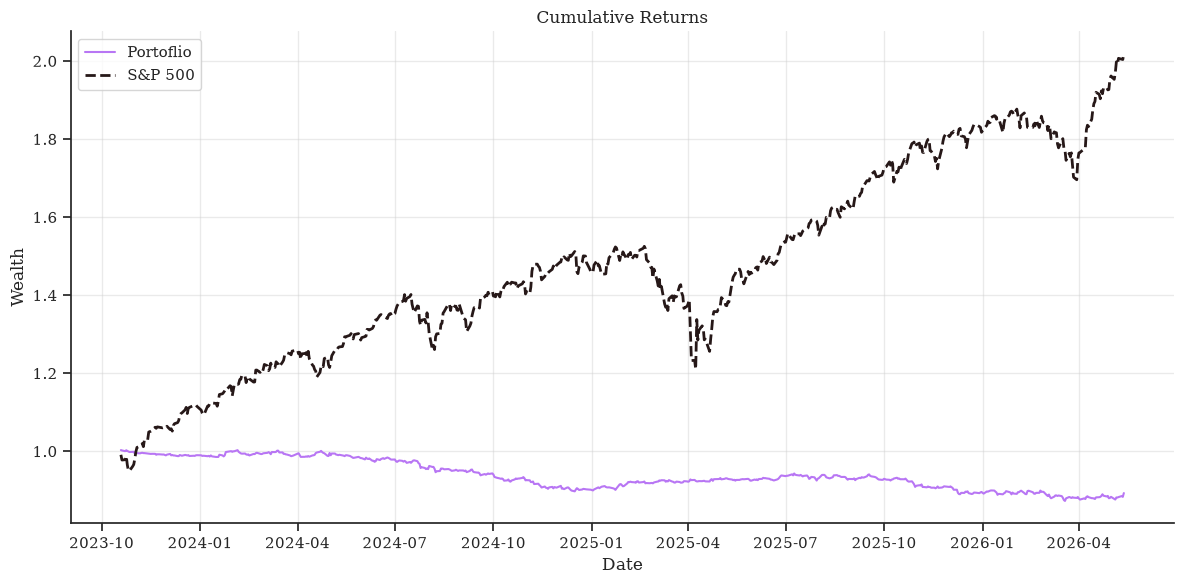

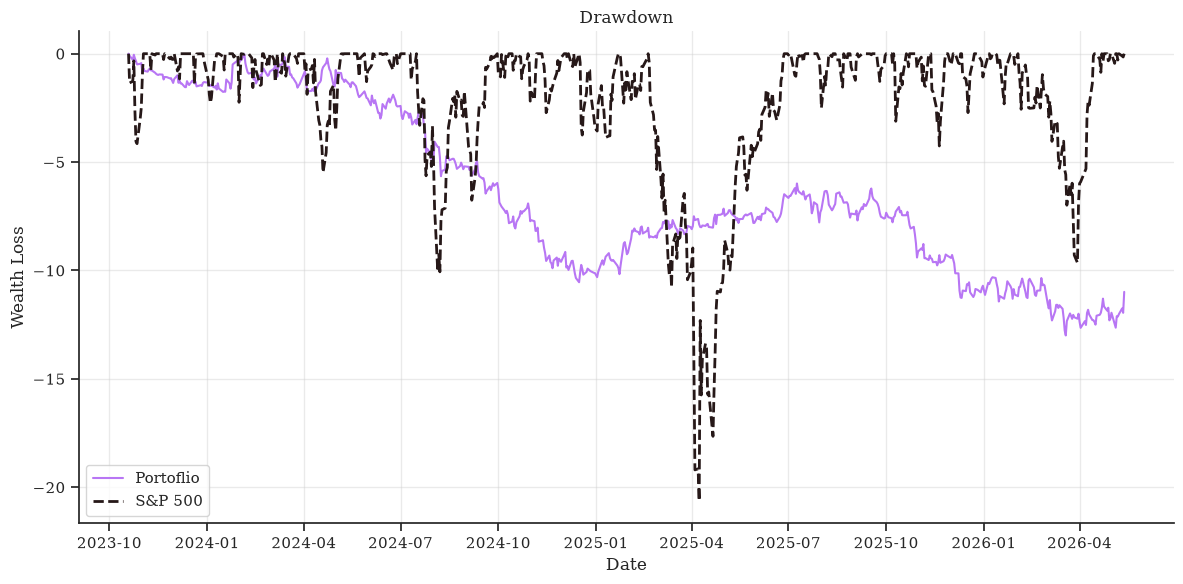

In [4]:
cumulative_returns(portfolio_net_return, market_portfolio_returns)
drawdown(portfolio_drawdown, market_portfolio_drawdown)

In [5]:

print(f"\n{'='*40}")
print(f"Portofolio")
print(f"{'='*40}")

print(f"Annualised Sharpe ratio : {portfolio_sharpe_ratio:.3f}")
print(f"Maximum drawdown : {portfolio_drawdown.min():.3%}")
print(f"Information Ratio : {portfolio_informatio_ratio:.3f}")
print(f"Annualised turnover : {portfolio_turnover.mean() * 252:.2%}")
print(f"Annualised return : {portfolio_net_return.mean() * 252:.3%}")
print(f"Annualised volatility : {portfolio_net_return.std() * np.sqrt(252):.3%}")
print(f"Effective assets : {portfolio_effective_number.mean():.2f}")

print(f"\n{'='*40}")
print(f"Market Portfolio")
print(f"{'='*40}")

print(f"Annualised Sharpe ratio : {market_portfolio_sharpe_ratio:.3f}")
print(f"Maximum drawdown : {market_portfolio_drawdown.min():.3%}")
print(f"Annualised return : {market_portfolio_returns.mean() * 252:.3%}")
print(f"Annualised volatility : {market_portfolio_returns.std() * np.sqrt(252):.3%}")


Portofolio
Annualised Sharpe ratio : -1.961
Maximum drawdown : -12.997%
Information Ratio : -1.837
Annualised turnover : 176.36%
Annualised return : -4.344%
Annualised volatility : 4.533%
Effective assets : 37.78

Market Portfolio
Annualised Sharpe ratio : 1.448
Maximum drawdown : -20.633%
Annualised return : 28.956%
Annualised volatility : 16.853%
